## Prerequisites

This notebook demonstrates how to invoke a **deployed real-time inference endpoint** on Azure for the LOINC Clinical Terminology Mapper model. Follow the steps below in order before running this notebook.

### Deployment Sequence

1. **Acquire the Azure Application Offer** — Subscribe to the *DICOM Images De-identification - Full* offer in the [Azure Marketplace](https://azuremarketplace.microsoft.com) to obtain the Solution Template.
2. **Launch guided deployment** — From the Marketplace listing, start the guided deployment flow for the solution.
3. **Supply configuration** — Complete the guided UX forms (defined by the offer's `createUiDefinition`) with the required parameters.
4. **Deploy resources** — Confirm deployment; Azure provisions the resources defined in the offer's `mainTemplate.json`.
5. **Wait for deployment to succeed** — Verify the deployment reaches a *Succeeded* state before proceeding. Note the endpoint name from the deployment output.
6. **Run this notebook** — Execute the cells below against the real-time inference endpoint provisioned by the deployment.

### Environment

- **Notebook runtime**: This notebook is intended to run in **Azure Machine Learning workspace notebooks** (e.g. via an Azure ML Studio compute instance or Studio notebooks).
- **Jupyter kernel**: Use a kernel with the `azure.ai.ml` Python package installed, for example **Python 3.10 — SDK v2** (`python310-sdkv2`).
- **Authentication**: The kernel must be authenticated to Azure so that Azure ML SDK calls succeed (e.g. `DefaultAzureCredential()`). The authenticated identity must be granted Azure RBAC permissions appropriate for reading the workspace and online endpoint configuration, and for retrieving endpoint credentials. Consult your organization's access-policy guidance and the [Azure ML endpoint credential documentation](https://learn.microsoft.com/azure/machine-learning/how-to-authenticate-online-endpoint) for details.
- **Network access**: The notebook's compute instance must be able to reach the endpoint's `scoring_uri` (no outbound firewall or VNET restrictions that block it).

## DICOM Images De-identification - Full

- **Model**: [dicom_deid_full_anonymization](https://nlp.johnsnowlabs.com/2025/02/19/dicom_deid_full_anonymization_en_3_4.html)

- **Model Description**: This pipeline is designed to de-identifying dicom fully.

In [ ]:
ENDPOINT_NAME = "<CUSTOMER_TO_PUT_DEPLOYED_ENDPOINT_NAME>"

### Input Format

The endpoint takes one DICOM file per request, sent as raw bytes:

- **Request**: the `.dcm` file content as the request body, with `Content-Type: application/octet-stream`.
- **Response**: the de-identified DICOM file content as the response body, with `Accept: application/octet-stream`.

### Authentication and Endpoint Lookup

The cell below uses `DefaultAzureCredential()` to authenticate to Azure, then retrieves the endpoint's scoring URI and primary access key from the workspace configuration. If you see authentication errors, verify that you are logged into Azure Cloud Shell / your compute instance and that your identity has sufficient role assignments on the workspace.

In [ ]:
from azure.ai.ml import MLClient
from azure.identity import DefaultAzureCredential
import os
import requests

ml_client = MLClient.from_config(DefaultAzureCredential())
endpoint_url = ml_client.online_endpoints.get(ENDPOINT_NAME).scoring_uri
key = ml_client.online_endpoints.get_keys(ENDPOINT_NAME).primary_key


def invoke_endpoint(dicom_file):
    with open(dicom_file, "rb") as f:
        dicom_data = f.read()

    output_file = f"outputs/real-time/{os.path.basename(dicom_file)}"
    os.makedirs(os.path.dirname(output_file), exist_ok=True)

    response = requests.post(
        endpoint_url,
        headers={
            "Authorization": f"Bearer {key}",
            "Content-Type": "application/octet-stream",
            "Accept": "application/octet-stream",
        },
        data=dicom_data,
        timeout=600,
    )
    response.raise_for_status()

    with open(output_file, "wb") as f:
        f.write(response.content)

    return output_file

In [ ]:
%pip install pydicom -q

In [ ]:
import matplotlib.pyplot as plt
import pydicom


def display_comparison(input_path, output_path, title=None):
    input_ds = pydicom.dcmread(input_path)
    output_ds = pydicom.dcmread(output_path)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(input_ds.pixel_array, cmap="gray")
    axes[0].set_title("Before")
    axes[0].axis("off")

    axes[1].imshow(output_ds.pixel_array, cmap="gray")
    axes[1].set_title("De-identified")
    axes[1].axis("off")

    if title:
        fig.suptitle(title)
    plt.show()

### Sample Data

In [ ]:
!wget --no-check-certificate https://github.com/JohnSnowLabs/visual-nlp-workshop/raw/refs/heads/master/jupyter/data/dicom/deidentify-medical-1.dcm -O deidentify-medical-1.dcm
!wget --no-check-certificate https://github.com/JohnSnowLabs/visual-nlp-workshop/raw/refs/heads/master/jupyter/data/dicom/deidentify-medical-2.dcm -O deidentify-medical-2.dcm

#### Example 1

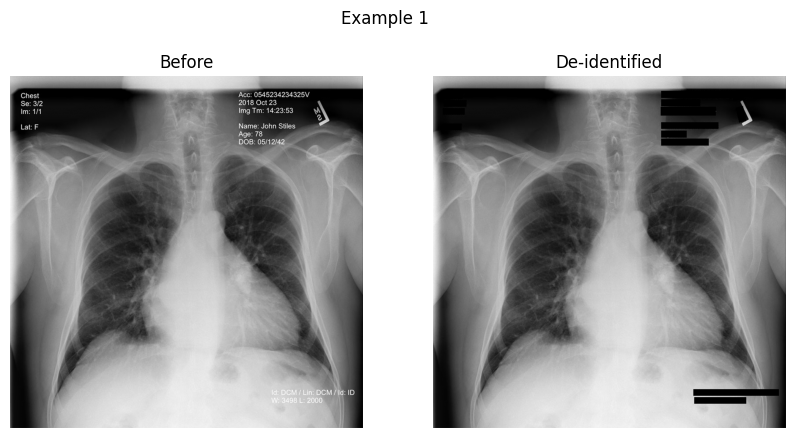

In [6]:
file_name = invoke_endpoint("./deidentify-medical-1.dcm")
display_comparison("./deidentify-medical-1.dcm", file_name, title="Example 1")

#### Example 2

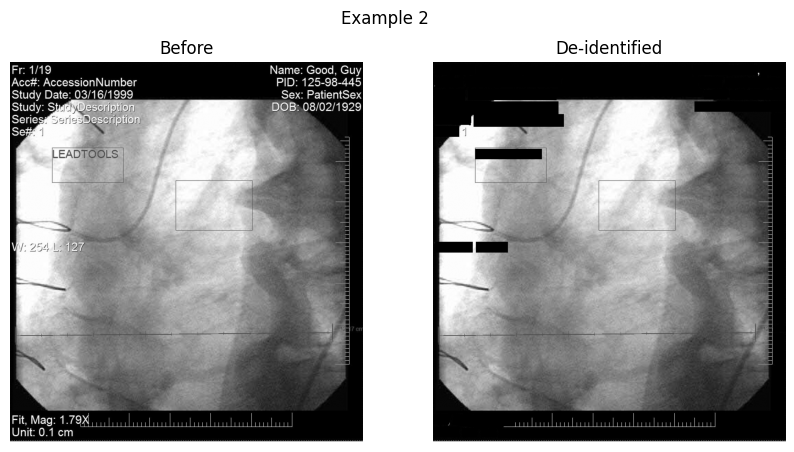

In [7]:
file_name = invoke_endpoint("./deidentify-medical-2.dcm")
display_comparison("./deidentify-medical-2.dcm", file_name, title="Example 2")